In [3]:
import pandas as pd

In [6]:
data = pd.read_csv("D:\churn-bigml-80.csv")



In [7]:
print(data.head())


  State  Account length  Area code International plan Voice mail plan  \
0    KS             128        415                 No             Yes   
1    OH             107        415                 No             Yes   
2    NJ             137        415                 No              No   
3    OH              84        408                Yes              No   
4    OK              75        415                Yes              No   

   Number vmail messages  Total day minutes  Total day calls  \
0                     25              265.1              110   
1                     26              161.6              123   
2                      0              243.4              114   
3                      0              299.4               71   
4                      0              166.7              113   

   Total day charge  Total eve minutes  Total eve calls  Total eve charge  \
0             45.07              197.4               99             16.78   
1             27.47   

In [8]:
print(data.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   

In [9]:
print(data['Churn'].value_counts())


Churn
False    2278
True      388
Name: count, dtype: int64


In [10]:
print(data.describe())


       Account length    Area code  Number vmail messages  Total day minutes  \
count     2666.000000  2666.000000            2666.000000         2666.00000   
mean       100.620405   437.438860               8.021755          179.48162   
std         39.563974    42.521018              13.612277           54.21035   
min          1.000000   408.000000               0.000000            0.00000   
25%         73.000000   408.000000               0.000000          143.40000   
50%        100.000000   415.000000               0.000000          179.95000   
75%        127.000000   510.000000              19.000000          215.90000   
max        243.000000   510.000000              50.000000          350.80000   

       Total day calls  Total day charge  Total eve minutes  Total eve calls  \
count      2666.000000       2666.000000        2666.000000      2666.000000   
mean        100.310203         30.512404         200.386159       100.023631   
std          19.988162          9.21573

In [11]:
data['Churn'] = data['Churn'].map({True:1, False:0})


In [12]:
for col in ['International plan','Voice mail plan']:
    data[col] = data[col].map({'Yes':1,'No':0})


In [13]:
data = pd.get_dummies(data, columns=['State','Area code'], drop_first=True)


In [14]:
print(data.isnull().sum())


Account length           0
International plan       0
Voice mail plan          0
Number vmail messages    0
Total day minutes        0
                        ..
State_WI                 0
State_WV                 0
State_WY                 0
Area code_415            0
Area code_510            0
Length: 70, dtype: int64


In [15]:
print(data.head())


   Account length  International plan  Voice mail plan  Number vmail messages  \
0             128                   0                1                     25   
1             107                   0                1                     26   
2             137                   0                0                      0   
3              84                   1                0                      0   
4              75                   1                0                      0   

   Total day minutes  Total day calls  Total day charge  Total eve minutes  \
0              265.1              110             45.07              197.4   
1              161.6              123             27.47              195.5   
2              243.4              114             41.38              121.2   
3              299.4               71             50.90               61.9   
4              166.7              113             28.34              148.3   

   Total eve calls  Total eve charge  ...  S

In [16]:
from sklearn.preprocessing import StandardScaler

In [17]:
X = data.drop('Churn', axis=1) 

In [18]:
y = data['Churn']  

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,y,test_size=0.2, 
    random_state=42)

In [22]:
print("Training set size:", X_train.shape)

Training set size: (2132, 69)


In [23]:
print("Testing set size:", X_test.shape)

Testing set size: (534, 69)


In [24]:
from sklearn.linear_model import LogisticRegression


In [25]:
from sklearn.ensemble import RandomForestClassifier

In [26]:
log_model = LogisticRegression()

In [27]:
log_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [28]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [29]:
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [30]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [31]:
y_pred_rf = rf_model.predict(X_test)

In [32]:
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.9363295880149812


In [33]:
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

Classification Report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.96       455
           1       1.00      0.57      0.73        79

    accuracy                           0.94       534
   macro avg       0.97      0.78      0.84       534
weighted avg       0.94      0.94      0.93       534



In [34]:
cm = confusion_matrix(y_test, y_pred_rf)

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

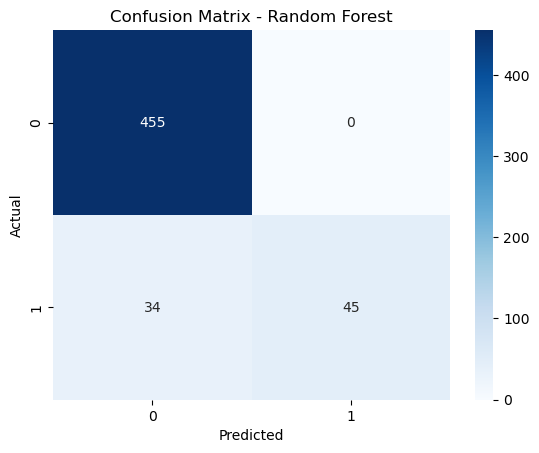

In [36]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [37]:
import numpy as np

In [38]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

In [39]:
for i in range(10):
    print(f"{X.columns[indices[i]]}: {importances[indices[i]]:.4f}")

Total day charge: 0.1200
Total day minutes: 0.1175
Customer service calls: 0.0865
International plan: 0.0776
Total eve charge: 0.0582
Total eve minutes: 0.0550
Total intl minutes: 0.0530
Total intl calls: 0.0431
Total intl charge: 0.0428
Total night minutes: 0.0394


In [40]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

In [41]:
for i in range(10):
    print(f"{X.columns[indices[i]]}: {importances[indices[i]]:.4f}")

Total day charge: 0.1200
Total day minutes: 0.1175
Customer service calls: 0.0865
International plan: 0.0776
Total eve charge: 0.0582
Total eve minutes: 0.0550
Total intl minutes: 0.0530
Total intl calls: 0.0431
Total intl charge: 0.0428
Total night minutes: 0.0394


In [42]:
import matplotlib.pyplot as plt

In [43]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

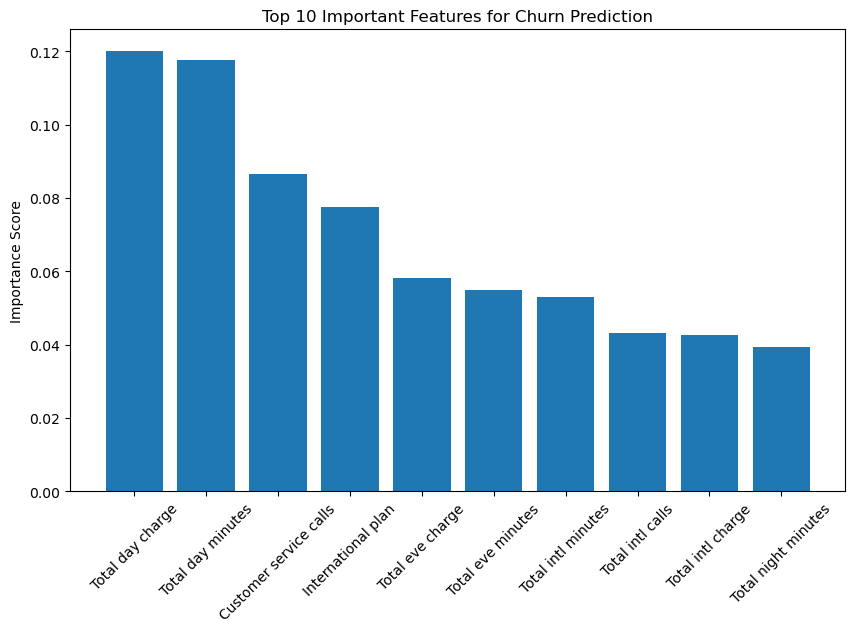

In [44]:
plt.figure(figsize=(10,6))
plt.title("Top 10 Important Features for Churn Prediction")
plt.bar(range(10), importances[indices[:10]], align='center')
plt.xticks(range(10), [X.columns[i] for i in indices[:10]], rotation=45)
plt.ylabel("Importance Score")
plt.show()

In [45]:

data.to_csv("cleaned_churn_dataset.csv", index=False)


In [46]:
import joblib

In [47]:
joblib.dump(rf_model, "random_forest_churn_model.pkl")

['random_forest_churn_model.pkl']

In [48]:
rf_model_loaded = joblib.load("random_forest_churn_model.pkl")